## 13. Uploaded current-date samples and final-stage snapshot

The three sources in repository-root `generated-test/` are preserved unchanged. Source identity, content relevance, printed dates and source-quality checks are separate. The certificate is accepted as `warranty` under the user-confirmed title-plus-period rule: both valid interpretations of its printed 2024–2027 window include the explicit 2026-11-15 as_of. Insurance wording and exact day/month format remain nonblocking interpretation notes. The auto-service PNG is entirely white, and the current receipt has an OCR savings error (`$0.88` → `880$`); those two remain excluded.

The default and full-page retry results are recorded separately. No important value is silently corrected and no source filename is used as date evidence. Original 12 human reviews remain untouched. See `FINAL_STAGE_1.md` for the finalized scope and `RAG_TESTING_PROMPT.md` for the next experiment.


generated-test/212_Warranty_simple_brown_landscape_3aee88aa90.jpg | relevance: relevant | admitted: True | unresolved source passages: []
Temporal assessment: within printed 2024-2027 period under either day/month interpretation; exact format unresolved
Review notes: Primary category follows the Warranty Certificate title, as clarified by the user. Insurance wording remains a later field-interpretation note and does not block admission.; 12.02 is day/month ambiguous, but both valid 2024-2027 windows contain the explicit 2026-11-15 as_of; preserve raw dates.; Template/provenance status is retained; acceptance is for the local experiment and does not prove real coverage.
generated-test/auto-service-receipt-2026-11-15.png | relevance: unreadable | admitted: False | unresolved source passages: []
Temporal assessment: unknown; the filename date is not document evidence
Review notes: Valid PNG but completely white. Supply a nonblank source; no OCR text or date may be invented.
generated-test


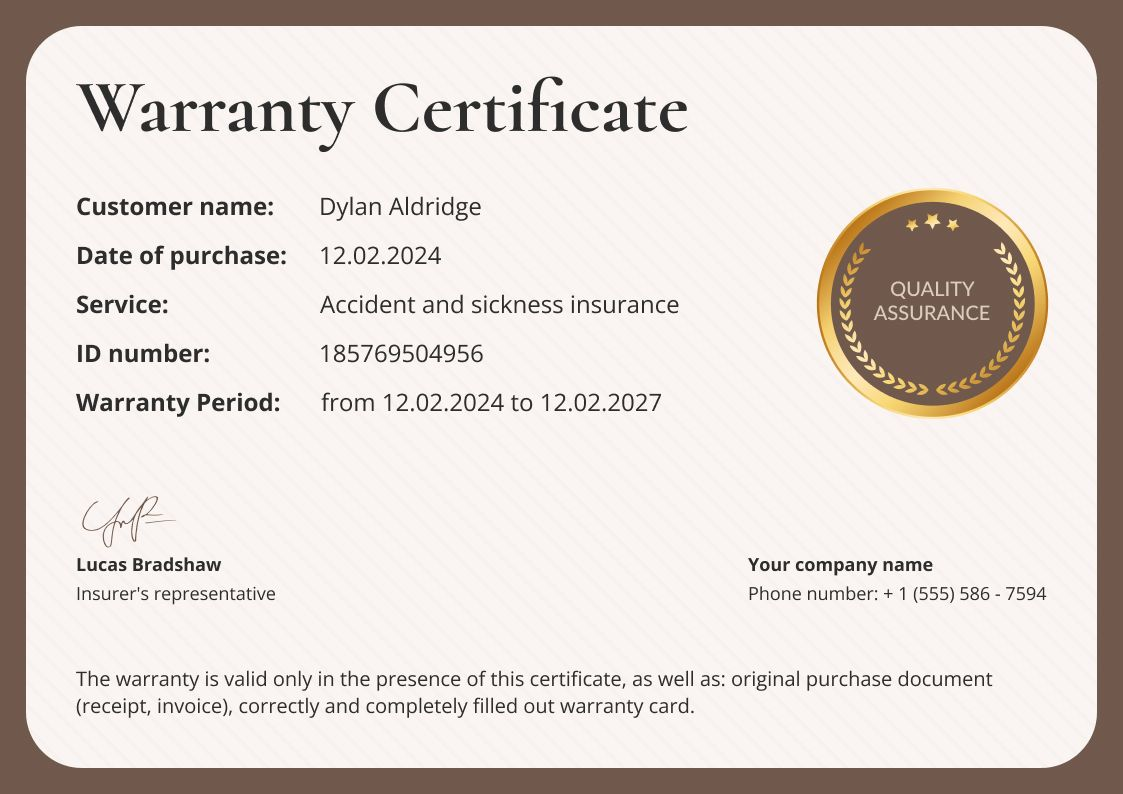
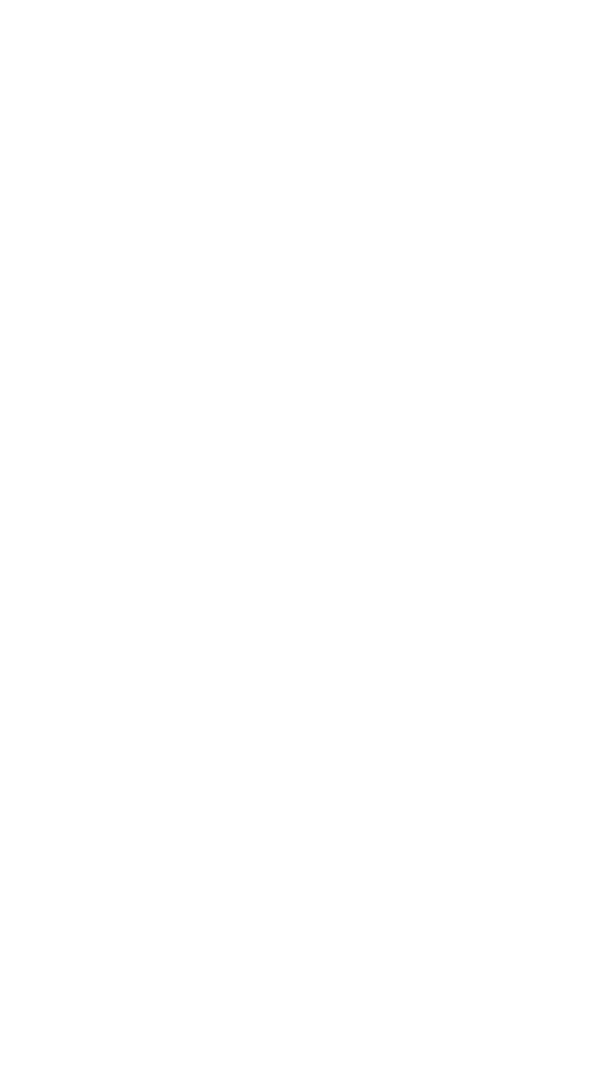
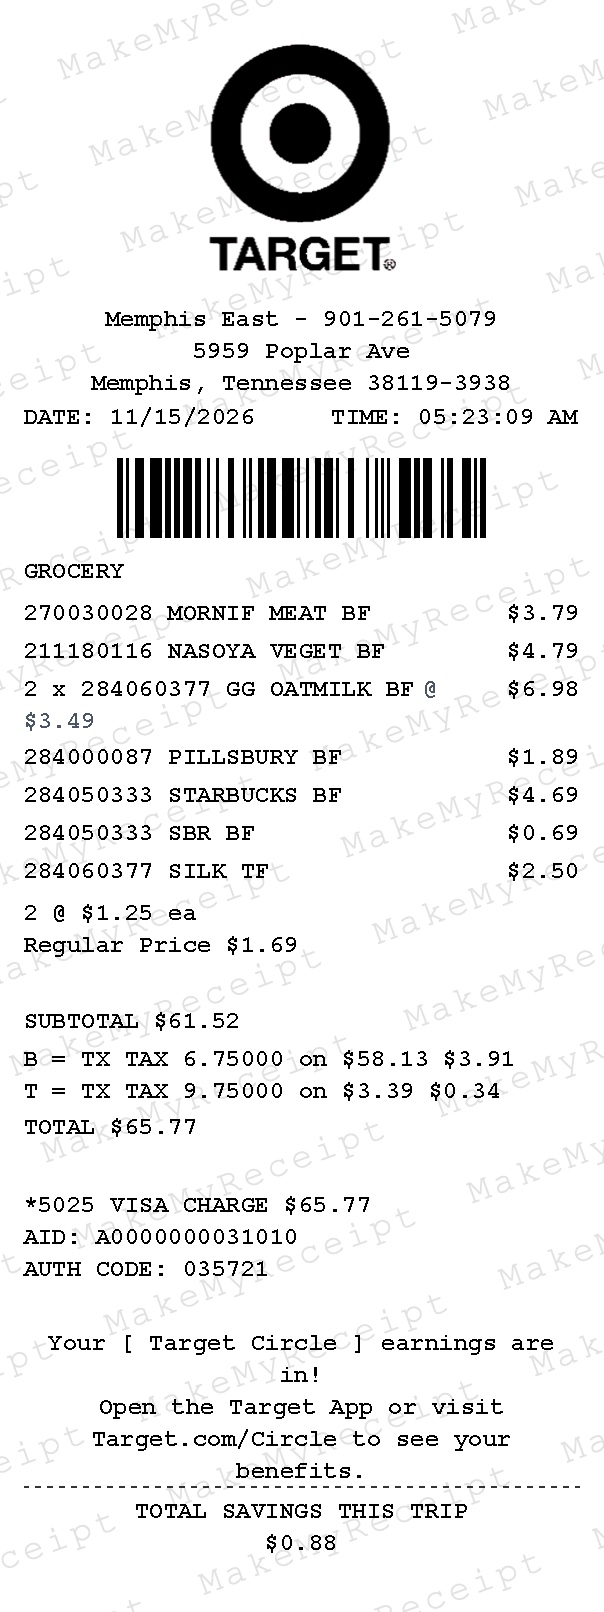

In [1]:
from pathlib import Path
import json
import sys
from IPython.display import HTML, display
sample_root = next(p for p in (Path.cwd(), *Path.cwd().parents)
                   if (p / 'Claimly_Three_Parts/contracts/llm.openapi.json').is_file())
sample_lab = sample_root / 'services/llm/parsing'
if str(sample_lab) not in sys.path:
    sys.path.insert(0, str(sample_lab))
from review_gallery import notebook_cards
from run_generated_tests import validate_case
sample_manifest = json.loads((sample_lab / 'generated_test_manifest.json').read_text())
for sample_case in sample_manifest['cases']:
    validate_case(sample_case, sample_root)
sample_report = json.loads((sample_lab / 'generated_test_results.json').read_text())
for sample in sample_report['cases']:
    missing = [c['quote'] for c in sample['source_passage_checks'] if not c['resolves_after_whitespace_normalization']]
    print(sample['relative_path'], '| relevance:', sample['relevance']['outcome'],
          '| admitted:', sample['acceptance_gate'], '| unresolved source passages:', missing)
    print('Temporal assessment:', sample['temporal_state'])
    print('Review notes:', '; '.join(sample['source_review_notes']))
sample_gallery = json.loads((sample_lab / 'runs/generated-final/gallery-data.json').read_text())
display(HTML(notebook_cards(sample_gallery)))